In [1]:
# 导入数据处理和可视化库

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 读取糖尿病分类数据集

url = "https://raw.githubusercontent.com/ibag422/Pima-Indians-Diabetes-Database/master/diabetes.csv"

df = pd.read_csv(url)

# 查看数据集基本信息

print("数据加载成功")
print("数据集形状：", df.shape)

print("\n字段名称：")
print(df.columns.tolist())

# 查看前五条数据

display(df.head())

数据加载成功
数据集形状： (768, 9)

字段名称：
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
# 分离输入特征和目标变量

X = df.drop(columns=["Outcome"])
y = df["Outcome"]

# 查看数据集大小

print("特征形状：", X.shape)
print("目标形状：", y.shape)

# 统计糖尿病类别数量

print("\n类别数量：")
print(y.value_counts().sort_index())

# 计算类别比例

print("\n类别比例：")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

特征形状： (768, 8)
目标形状： (768,)

类别数量：
Outcome
0    500
1    268
Name: count, dtype: int64

类别比例：
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


数据集信息：
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

描述性统计：


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



缺失值总数： 0
重复记录数： 0

各医学指标的零值数量：
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


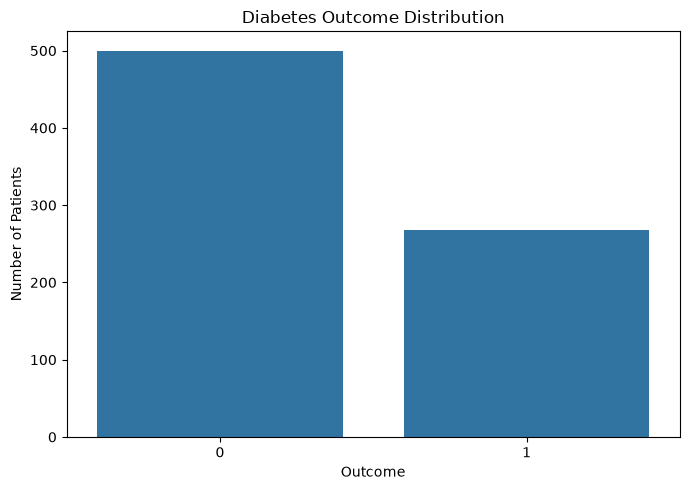

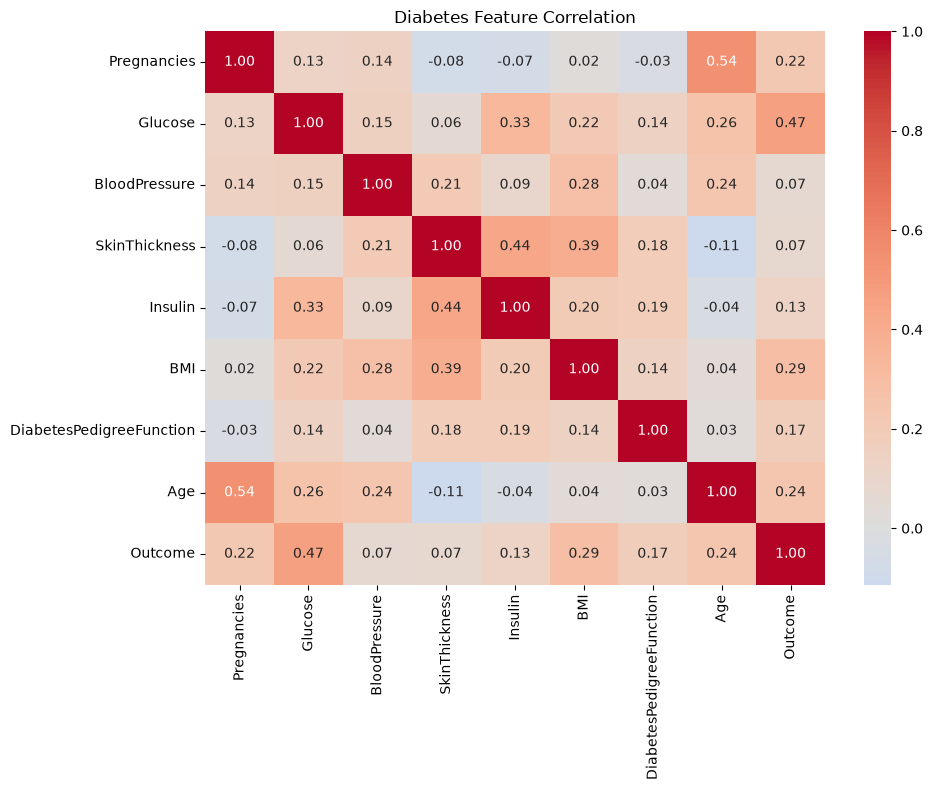


数据检查与可视化完成


In [3]:
# 检查数据集基本情况

print("数据集信息：")
df.info()

print("\n描述性统计：")
display(df.describe())

print("\n缺失值总数：", df.isnull().sum().sum())
print("重复记录数：", df.duplicated().sum())

# 检查医学指标中的异常零值

zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print("\n各医学指标的零值数量：")
print((df[zero_columns] == 0).sum())

# 创建图片保存目录

from pathlib import Path

figures_dir = Path("../results/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# 绘制糖尿病类别分布图

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Outcome"
)

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")

plt.tight_layout()

plt.savefig(
    figures_dir / "diabetes_outcome_distribution.png",
    dpi=300
)

plt.show()

# 绘制各特征与目标变量的相关性热力图

plt.figure(figsize=(10, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Diabetes Feature Correlation")

plt.tight_layout()

plt.savefig(
    figures_dir / "diabetes_correlation_heatmap.png",
    dpi=300
)

plt.show()

print("\n数据检查与可视化完成")

In [4]:
# 导入机器学习工具

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 将医学指标中的异常零值标记为缺失值

X_model = X.copy()
X_model[zero_columns] = X_model[zero_columns].replace(0, np.nan)

y_model = y.copy()

# 按类别比例划分训练集和测试集

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.2,
    random_state=42,
    stratify=y_model
)

# 配置五折分层交叉验证

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 构建缺失值填补和标准化流程

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("训练集：", X_train.shape)
print("测试集：", X_test.shape)
print("五折分层交叉验证配置成功")

训练集： (614, 8)
测试集： (154, 8)
五折分层交叉验证配置成功


In [5]:
# 定义三个分类模型

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        random_state=42
    )
}

# 定义评价指标

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

# 执行五折交叉验证

pipelines = {}
cv_results = {}
comparison_results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipelines[name] = pipeline

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    cv_results[name] = scores

    result = {"Model": name}

    for metric in scoring:
        values = scores[f"test_{metric}"]

        result[f"{metric}_Mean"] = values.mean()
        result[f"{metric}_Std"] = values.std()

    comparison_results.append(result)

    print(f"{name} 交叉验证完成")

# 汇总交叉验证结果

cv_comparison = pd.DataFrame(comparison_results)

display(cv_comparison.round(4))

# 保存模型对比表

cv_comparison.to_csv(
    "../results/diabetes_cv_comparison.csv",
    index=False
)

print("模型对比 CSV 保存成功")

Logistic Regression 交叉验证完成
Decision Tree 交叉验证完成
Random Forest 交叉验证完成


,Model,Accuracy_Mean,Accuracy_Std,Precision_Mean,Precision_Std,Recall_Mean,Recall_Std,F1_Mean,F1_Std,ROC_AUC_Mean,ROC_AUC_Std
0,Logistic Regression,0.7882,0.0191,0.7638,0.0598,0.5748,0.0227,0.6545,0.0244,0.8434,0.0185
1,Decision Tree,0.7296,0.0168,0.6271,0.0260,0.5602,0.0843,0.5877,0.0479,0.7706,0.0286
2,Random Forest,0.7671,0.0201,0.7052,0.0563,0.5795,0.0240,0.6347,0.0227,0.8263,0.0250


模型对比 CSV 保存成功


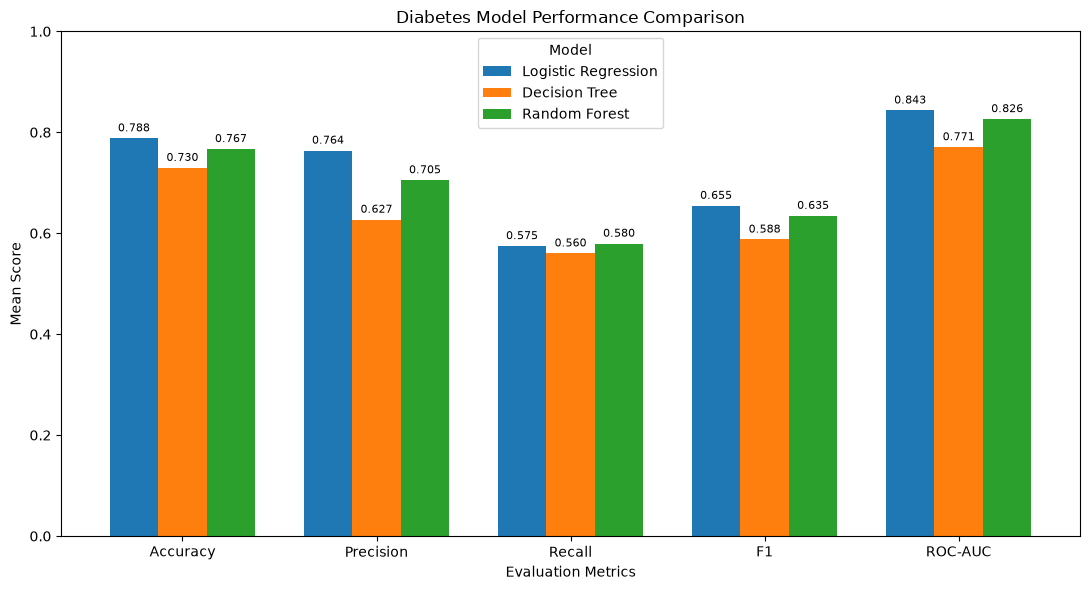

In [6]:
# 整理模型性能指标

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC"
]

plot_data = cv_comparison.set_index("Model")[
    [f"{metric}_Mean" for metric in metrics]
].copy()

plot_data.columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

# 绘制五折交叉验证模型对比图

ax = plot_data.T.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

plt.title("Diabetes Model Performance Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Mean Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Model")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=8
    )

plt.tight_layout()

# 保存模型对比图

plt.savefig(
    "../results/figures/diabetes_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
# 导入模型评价工具

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

# 保存模型及预测结果

trained_models = {}
test_predictions = {}
test_probabilities = {}
test_results = []

# 在完整训练集上重新训练模型

for name, pipeline in pipelines.items():

    model = clone(pipeline)
    model.fit(X_train, y_train)

    # 使用独立测试集预测

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    trained_models[name] = model
    test_predictions[name] = y_pred
    test_probabilities[name] = y_prob

    # 计算分类评价指标

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"{name} 测试完成")

# 汇总并保存测试集结果

test_comparison = pd.DataFrame(test_results)

display(test_comparison.round(4))

test_comparison.to_csv(
    "../results/diabetes_test_comparison.csv",
    index=False
)

print("测试集模型对比结果保存成功")

Logistic Regression 测试完成
Decision Tree 测试完成
Random Forest 测试完成


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.7078,0.6000,0.5000,0.5455,0.8130
1,Decision Tree,0.7597,0.6393,0.7222,0.6783,0.7622
2,Random Forest,0.7338,0.6585,0.5000,0.5684,0.8065


测试集模型对比结果保存成功


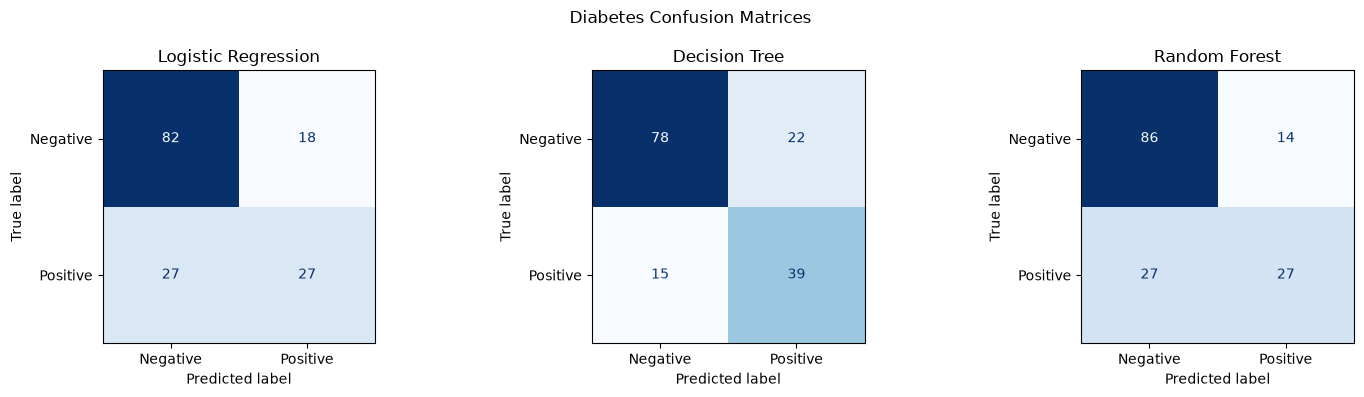

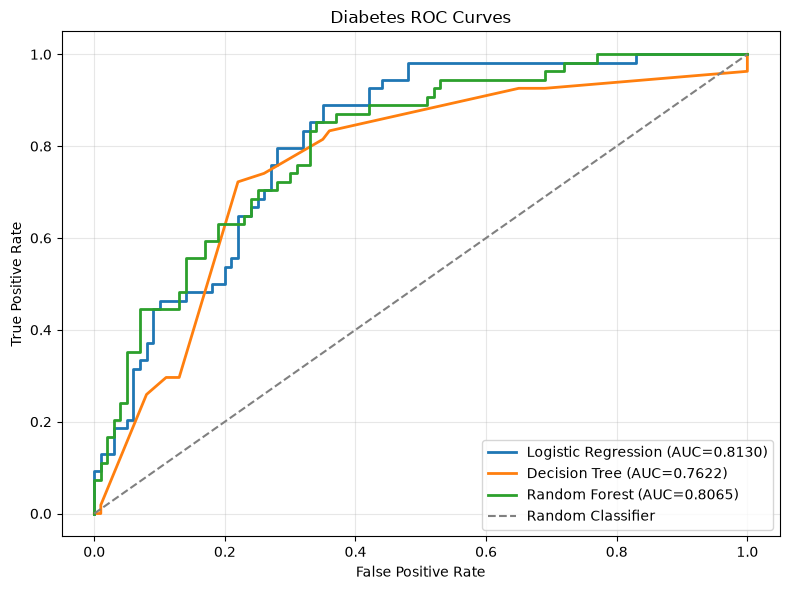

混淆矩阵和 ROC 曲线保存成功


In [8]:
# 绘制三个模型的混淆矩阵

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y_pred) in zip(
    axes,
    test_predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name)

plt.suptitle("Diabetes Confusion Matrices")
plt.tight_layout()

plt.savefig(
    "../results/figures/diabetes_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 绘制三个模型的 ROC 曲线

plt.figure(figsize=(8, 6))

for name, y_prob in test_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC={auc_score:.4f})"
    )

# 添加随机分类参考线

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray",
    label="Random Classifier"
)

plt.title("Diabetes ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../results/figures/diabetes_roc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("混淆矩阵和 ROC 曲线保存成功")